# Week 1 – ML Fundamentals & Basic Supervised Models
Work through this top to bottom. **Type the code yourself where you can, and change things to see what breaks.** Cells marked 🧪 are exercises for you.

Note: the Boston Housing dataset was removed from scikit-learn (v1.2+) because of ethical concerns about one of its features. We use **California Housing** instead; it is the same kind of regression problem.

## 0. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
sns.set_theme(style="whitegrid")
np.random.seed(42)

## 1. EDA on Iris (classification dataset)

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df.shape); display(df.head())
display(df.describe()); print(df.isna().sum().sum(), "missing values")
print(df['species'].value_counts())

(150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


0 missing values
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


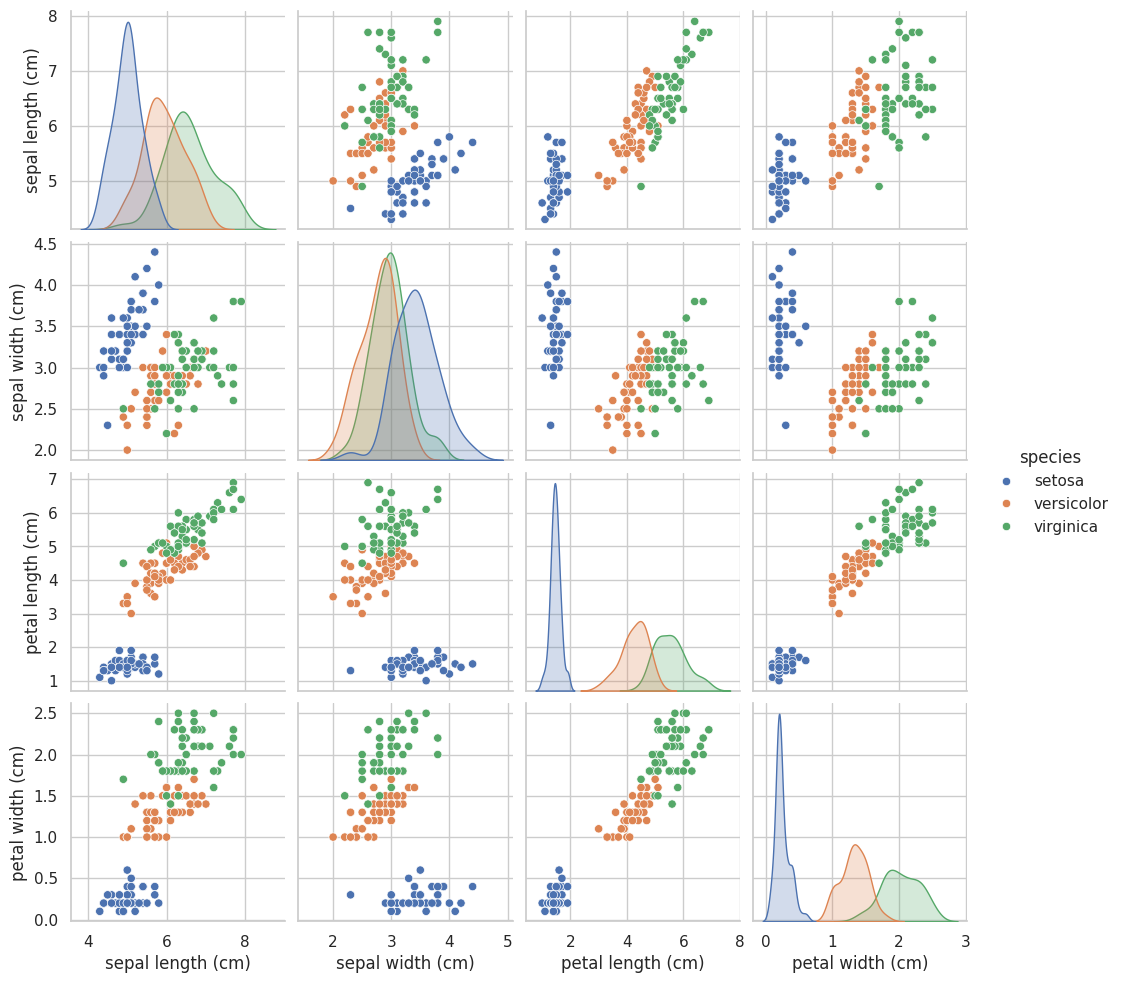

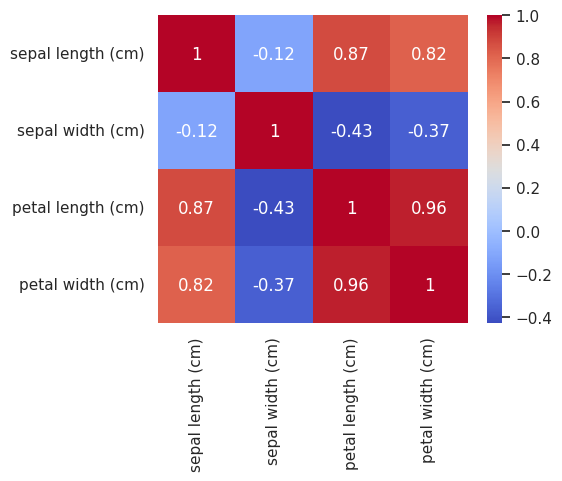

In [3]:
sns.pairplot(df.drop(columns='target'), hue='species'); plt.show()
plt.figure(figsize=(5,4)); sns.heatmap(df.drop(columns=['species','target']).corr(), annot=True, cmap='coolwarm'); plt.show()

🧪 **Exercise:** Which two features separate the species best? Which pair of species overlaps most? Write your answer here.

## 2. EDA on California Housing (regression dataset)

In [4]:
import pandas as pd

# Download the original California Housing CSV
url = "https://raw.githubusercontent.com/akmand/datasets/main/california_housing.csv"

raw = pd.read_csv(url)

# Create the same dataframe format as sklearn
hdf = pd.DataFrame({
    "MedInc": raw["median_income"],
    "HouseAge": raw["housing_median_age"],
    "AveRooms": raw["total_rooms"] / raw["households"],
    "AveBedrms": raw["total_bedrooms"] / raw["households"],
    "Population": raw["population"],
    "AveOccup": raw["population"] / raw["households"],
    "Latitude": raw["latitude"],
    "Longitude": raw["longitude"],
    "MedHouseVal": raw["median_house_value"] / 100000
})

# Save as CSV
hdf.to_csv("california_housing_exact.csv", index=False)

print(hdf.shape)
display(hdf.head())
display(hdf.describe())

# Download the CSV to your computer
from google.colab import files
files.download("california_housing_exact.csv")

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.097062,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.476104,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006029,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048889,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099631,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import pandas as pd

hdf = pd.read_csv("california_housing_exact.csv")

print(hdf.shape)
display(hdf.head())
display(hdf.describe())

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.097062,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.476104,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006029,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048889,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099631,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

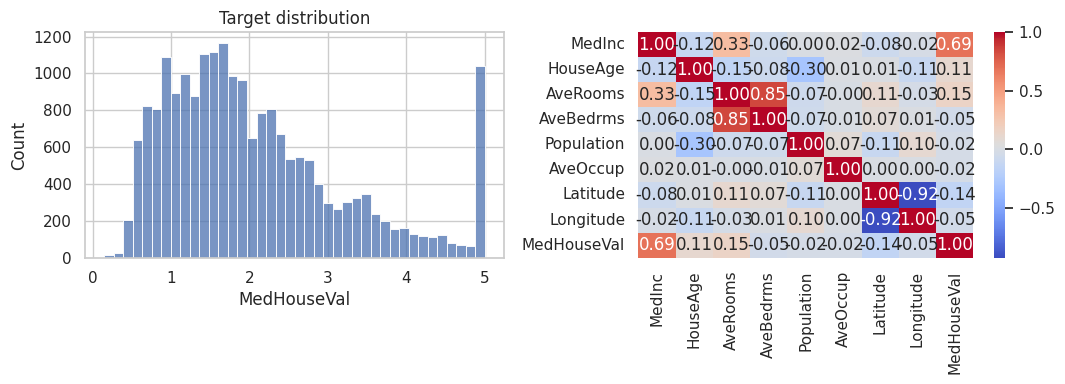

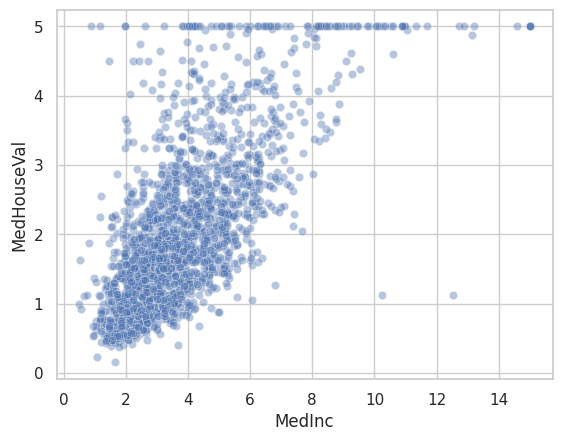

In [7]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
sns.histplot(hdf['MedHouseVal'], bins=40, ax=ax[0]); ax[0].set_title('Target distribution')
sns.heatmap(hdf.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1]); plt.tight_layout(); plt.show()
sns.scatterplot(data=hdf.sample(2000, random_state=1), x='MedInc', y='MedHouseVal', alpha=.4); plt.show()

## 3. Gradient descent from scratch (Batch vs SGD)
Idea: for linear regression we minimise MSE by repeatedly stepping *against* the gradient: `w ← w − lr · ∂Loss/∂w`.
- **Batch GD**: gradient from all samples each step (smooth, slower per step)
- **SGD**: gradient from 1 sample per step (noisy, fast, can escape shallow minima)
- **Mini-batch**: in between; this is what deep learning uses

Batch GD weights: [2.06855817 0.79398939] | SGD weights: [2.14296376 0.76752717]
sklearn weights : 2.068558169089147 [0.79398939]


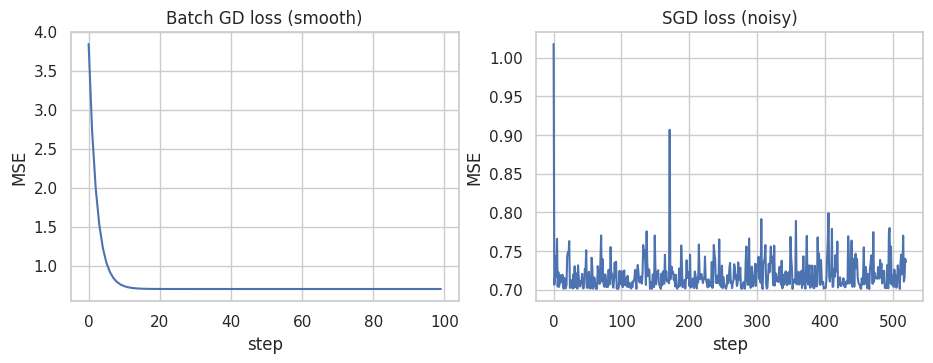

In [8]:
X = hdf[['MedInc']].values; y = hdf['MedHouseVal'].values
Xs = StandardScaler().fit_transform(X)            # scaling matters for gradient descent
Xb = np.c_[np.ones(len(Xs)), Xs]                  # add bias column

def batch_gd(Xb, y, lr=0.1, epochs=100):
    w = np.zeros(Xb.shape[1]); losses=[]
    for _ in range(epochs):
        grad = 2/len(y) * Xb.T @ (Xb@w - y)
        w -= lr*grad; losses.append(np.mean((Xb@w-y)**2))
    return w, losses

def sgd(Xb, y, lr=0.01, epochs=5):
    w = np.zeros(Xb.shape[1]); losses=[]
    for _ in range(epochs):
        for i in np.random.permutation(len(y)):
            grad = 2 * Xb[i] * (Xb[i]@w - y[i])
            w -= lr*grad
            if i % 200 == 0: losses.append(np.mean((Xb@w-y)**2))
    return w, losses

wb, lb = batch_gd(Xb, y); ws, ls = sgd(Xb, y)
print("Batch GD weights:", wb, "| SGD weights:", ws)
print("sklearn weights :", LinearRegression().fit(Xs,y).intercept_, LinearRegression().fit(Xs,y).coef_)
fig, ax = plt.subplots(1,2, figsize=(11,3.5))
ax[0].plot(lb); ax[0].set_title('Batch GD loss (smooth)'); ax[1].plot(ls); ax[1].set_title('SGD loss (noisy)')
for a in ax: a.set_xlabel('step'); a.set_ylabel('MSE')
plt.show()

## 4. Linear Regression (California Housing)

In [9]:
from sklearn.impute import SimpleImputer

In [10]:
Xf = hdf.drop(columns='MedHouseVal')
yf = hdf['MedHouseVal']

Xtr, Xte, ytr, yte = train_test_split(
    Xf, yf, test_size=0.2, random_state=42
)

lin = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LinearRegression()
).fit(Xtr, ytr)

pred = lin.predict(Xte)

mse = mean_squared_error(yte, pred)

print(
    f"MSE={mse:.3f}  "
    f"RMSE={np.sqrt(mse):.3f}  "
    f"R2={r2_score(yte, pred):.3f}"
)

print(
    "Train R2:",
    round(lin.score(Xtr, ytr), 3),
    "| Test R2:",
    round(lin.score(Xte, yte), 3)
)

MSE=0.556  RMSE=0.746  R2=0.576
Train R2: 0.613 | Test R2: 0.576


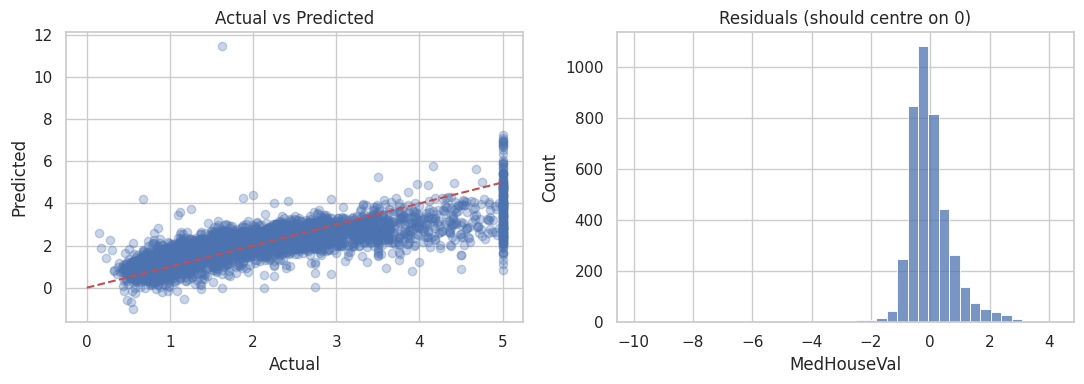

In [11]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].scatter(yte, pred, alpha=.3); ax[0].plot([0,5],[0,5],'r--'); ax[0].set(xlabel='Actual', ylabel='Predicted', title='Actual vs Predicted')
sns.histplot(yte-pred, bins=40, ax=ax[1]); ax[1].set_title('Residuals (should centre on 0)')
plt.tight_layout(); plt.show()

## 5. Bias–Variance: underfitting vs overfitting, visually

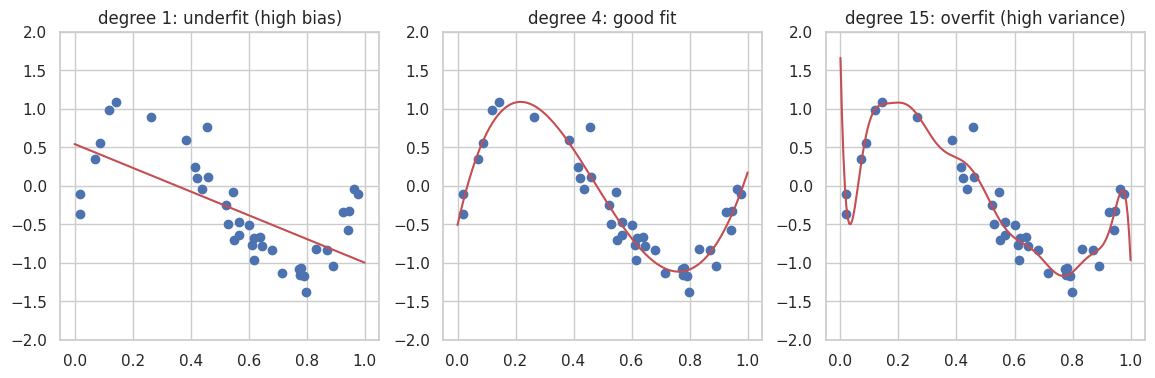

In [12]:
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0,1,40)); yy = np.sin(2*np.pi*x) + rng.normal(0,.25,40)
xt = np.linspace(0,1,200)
fig, ax = plt.subplots(1,3, figsize=(14,4))
for a,d in zip(ax,[1,4,15]):
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(x[:,None], yy)
    a.scatter(x,yy); a.plot(xt, m.predict(xt[:,None]), 'r'); a.set_ylim(-2,2)
    a.set_title(f'degree {d}: ' + {1:'underfit (high bias)',4:'good fit',15:'overfit (high variance)'}[d])
plt.show()

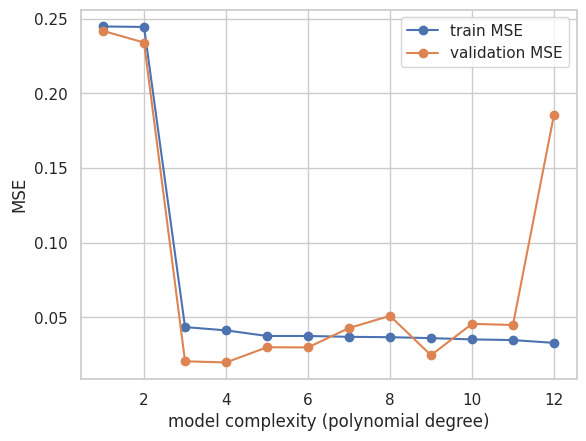

In [13]:
# Validation-curve view: train error keeps falling, test error turns back up
xtr, xva, ytr2, yva = train_test_split(x, yy, test_size=.3, random_state=1)
degs = range(1,13); tr=[]; va=[]
for d in degs:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(xtr[:,None], ytr2)
    tr.append(mean_squared_error(ytr2, m.predict(xtr[:,None]))); va.append(mean_squared_error(yva, m.predict(xva[:,None])))
plt.plot(degs, tr, 'o-', label='train MSE'); plt.plot(degs, va, 'o-', label='validation MSE')
plt.xlabel('model complexity (polynomial degree)'); plt.ylabel('MSE'); plt.legend(); plt.show()

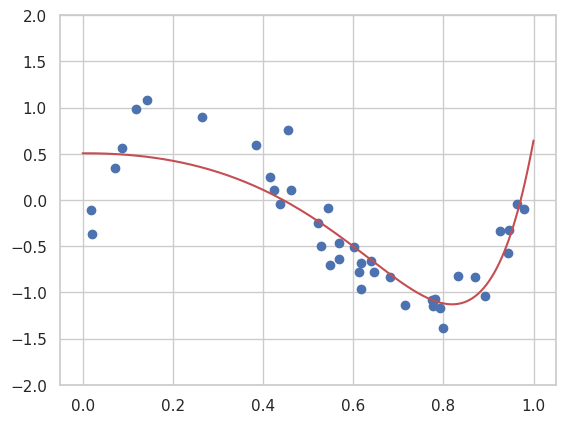

In [14]:
from sklearn.linear_model import Ridge
m = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=1.0)).fit(x[:,None], yy)
plt.scatter(x, yy); plt.plot(xt, m.predict(xt[:,None]), 'r'); plt.ylim(-2,2); plt.show()

## 6. Logistic Regression (Iris)

Accuracy: 0.9210526315789473
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



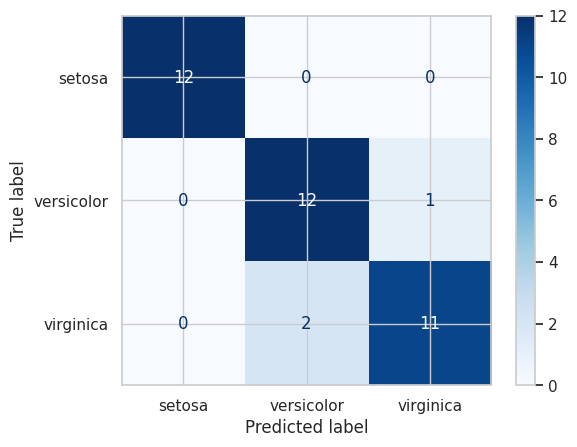

In [15]:
Xi = iris.data; yi = iris.target
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=.25, random_state=42, stratify=yi)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(Xtr, ytr)
p = clf.predict(Xte)
print("Accuracy:", accuracy_score(yte,p))
print(classification_report(yte,p,target_names=iris.target_names))
ConfusionMatrixDisplay(confusion_matrix(yte,p), display_labels=iris.target_names).plot(cmap='Blues'); plt.show()

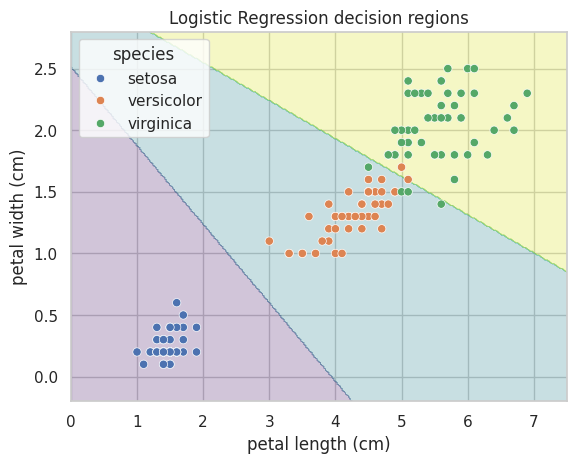

In [16]:
# Decision boundary using 2 features so we can draw it
f = ['petal length (cm)','petal width (cm)']
c2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(iris.data[f], yi)
g1,g2 = np.meshgrid(np.linspace(0,7.5,300), np.linspace(-.2,2.8,300))
Z = c2.predict(pd.DataFrame(np.c_[g1.ravel(), g2.ravel()], columns=f)).reshape(g1.shape)
plt.contourf(g1,g2,Z,alpha=.25,cmap='viridis'); sns.scatterplot(x=iris.data[f[0]], y=iris.data[f[1]], hue=df['species'])
plt.xlabel(f[0]); plt.ylabel(f[1]); plt.title('Logistic Regression decision regions'); plt.show()

In [17]:
# Binary metrics by hand: versicolor(1) vs the rest, to understand precision/recall
yb = (yi==1).astype(int)
Xtr, Xte, ytr, yte = train_test_split(Xi, yb, test_size=.3, random_state=0, stratify=yb)
cb = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(Xtr,ytr)
pb = cb.predict(Xte); tn,fp,fn,tp = confusion_matrix(yte,pb).ravel()
print(f"TP={tp} FP={fp} FN={fn} TN={tn}")
print("precision =", tp/(tp+fp), "| recall =", tp/(tp+fn), "| accuracy =", (tp+tn)/(tp+tn+fp+fn))
print("sklearn   :", precision_score(yte,pb), recall_score(yte,pb), f1_score(yte,pb))

TP=7 FP=5 FN=8 TN=25
precision = 0.5833333333333334 | recall = 0.4666666666666667 | accuracy = 0.7111111111111111
sklearn   : 0.5833333333333334 0.4666666666666667 0.5185185185185185


🧪 **Exercise:** In your own words, when would you care more about *recall* than *precision*? (Think cancer screening vs spam filter.)

## 7. Linear vs Logistic: the comparison your checkpoint needs

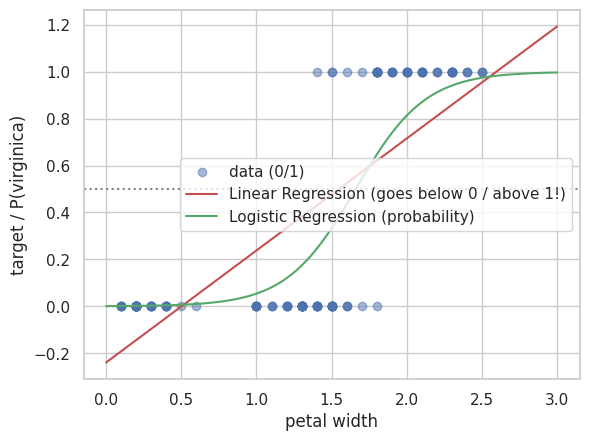

In [18]:
# Same binary problem (petal width -> is it virginica?) solved by both models
xw = iris.data[['petal width (cm)']].values; yv = (yi==2).astype(int)
lr_lin = LinearRegression().fit(xw, yv); lr_log = LogisticRegression().fit(xw, yv)
xs = np.linspace(0,3,200)[:,None]
plt.scatter(xw, yv, alpha=.5, label='data (0/1)')
plt.plot(xs, lr_lin.predict(xs), 'r', label='Linear Regression (goes below 0 / above 1!)')
plt.plot(xs, lr_log.predict_proba(xs)[:,1], 'g', label='Logistic Regression (probability)')
plt.axhline(.5, ls=':', c='gray'); plt.xlabel('petal width'); plt.ylabel('target / P(virginica)'); plt.legend(); plt.show()

### Comparison table (fill in / edit in your own words)
| | Linear Regression | Logistic Regression |
|---|---|---|
| Task | Predict a continuous number | Predict a class / probability |
| Output | Any real number | Value in (0, 1) via sigmoid |
| Loss | MSE | Log-loss (cross-entropy) |
| Metrics | MSE, RMSE, R² | Accuracy, precision, recall, F1 |
| Optimised by | Closed form or gradient descent | Gradient descent (no closed form) |

## 8. Checkpoint: explain in your own words
**Bias–variance tradeoff:** Bias and variance are two types of errors in machine learning. Bias occurs when a model is too simple to learn the actual pattern in the data. Variance occurs when a model learns the training data too closely, including noise and small changes. High bias can lead to underfitting, while high variance can lead to overfitting. The bias–variance tradeoff means finding a balance between the two so that the model performs well on both training and unseen data.

**Accuracy / Precision / Recall / F1:** Suppose a model predicts whether a person has a disease. Out of 100 people, 20 actually have the disease. The model correctly identifies 15 of those 20 people, but it also incorrectly predicts that 5 healthy people have the disease.
Assume the model correctly identifies 75 healthy people, too.
Accuracy: How many predictions are correct overall
Precision: Out of all positive predictions, how many are actually positive?
Recall: Out of all actual positive cases, how many did the model find?
F1-score: A balance between precision and recall
Here:
- TP (true positives) = 15
- TN (true negatives) = 75
- FP (false positives) = 5
- FN (false negatives) = 5
Let's calculate:
- Accuracy = (15 + 75) / 100 = 90%
- Precision = 15 / (15 + 5) = 75%
- Recall = 15 / (15 + 5) = 75%
- F1-score = 75%
In simple words, accuracy measures overall correctness, precision measures the reliability of positive predictions, recall measures how many actual positive cases are found, and F1-score balances precision and recall.

**MSE and R²:** Mean Squared Error (MSE) measures the average squared difference between actual values and predicted values. A smaller MSE generally means the predictions are closer to the actual values.
\[
MSE=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat y_i)^2
\]

For example, if the actual value is 10 and the model predicts 8, the squared error is \((10-8)^2=4\).
R² (coefficient of determination) measures how well a regression model explains the variation in the target values. An \(R^2\) of 1 means a perfect fit, 0 means the model performs like predicting the mean of the target on the evaluated data, and a negative value means it performs worse than that mean baseline.

**Overfitting vs underfitting:** Overfitting happens when a model learns the training data too closely, including noise. It performs very well on training data but poorly on unseen data. For example, a decision tree that memorises its training examples may overfit.
Underfitting happens when a model is too simple to learn the important patterns in the data. It performs poorly on both training and test data. For example, using a straight line to model a strongly curved relationship may underfit.